# Day 07 — Visualization (Matplotlib & Seaborn), TensorFlow Intro & a CSV Analysis Task



 pip install matplotlib seaborn tensorflow


In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"        # quieter TensorFlow logs
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
rng = np.random.default_rng(42)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.3 | pandas 3.0.5


---
## Part 1 — Matplotlib

Matplotlib is Python's foundational plotting library. The two key objects:
- **Figure**: the whole canvas.
- **Axes**: a single plot inside the figure (with x/y axes, title, labels, data).



### 1.1  line plot

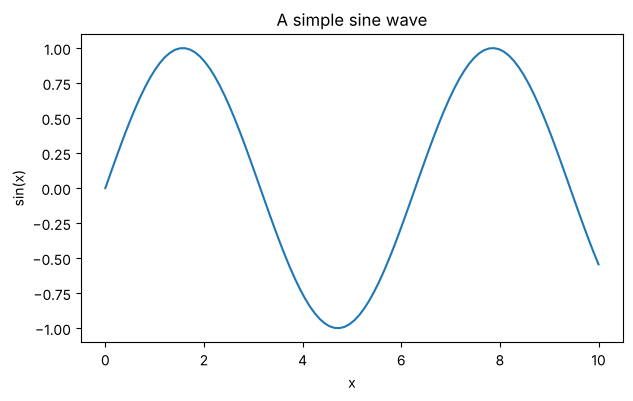

In [2]:
x = np.linspace(0, 10, 100)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, np.sin(x))
ax.set_title("A simple sine wave")
ax.set_xlabel("x")
ax.set_ylabel("sin(x)")
plt.show()

### 1.2 Multiple lines, styles, legend and grid

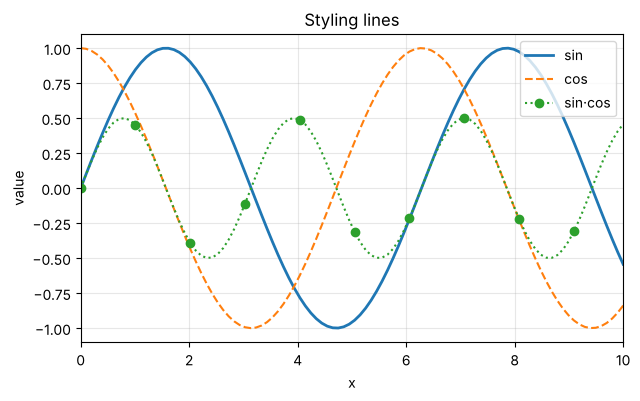

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(x, np.sin(x), label="sin", color="tab:blue", linewidth=2)
ax.plot(x, np.cos(x), label="cos", color="tab:orange", linestyle="--")
ax.plot(x, np.sin(x) * np.cos(x), label="sin·cos", color="tab:green", linestyle=":", marker="o", markevery=10)

ax.set_title("Styling lines")
ax.set_xlabel("x")
ax.set_ylabel("value")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
ax.set_xlim(0, 10)
plt.show()

### 1.3 Scatter plot

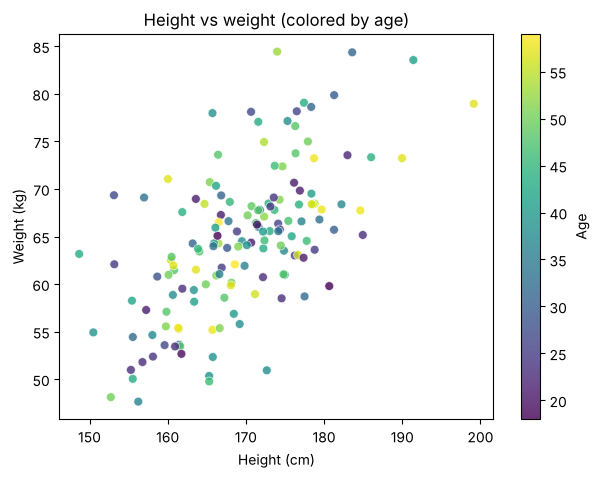

In [4]:
n = 150
height = rng.normal(170, 10, n)
weight = 0.5 * height - 20 + rng.normal(0, 6, n)
age = rng.integers(18, 60, n)

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(height, weight, c=age, cmap="viridis", s=40, alpha=0.8, edgecolor="white", linewidth=0.5)
fig.colorbar(sc, ax=ax, label="Age")
ax.set_title("Height vs weight (colored by age)")
ax.set_xlabel("Height (cm)")
ax.set_ylabel("Weight (kg)")
plt.show()

### 1.4 Bar charts

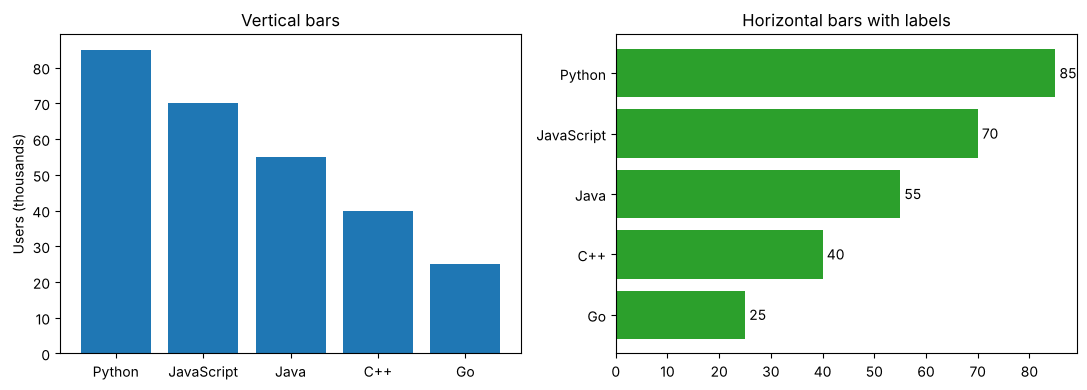

In [5]:
languages = ["Python", "JavaScript", "Java", "C++", "Go"]
users = [85, 70, 55, 40, 25]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.bar(languages, users, color="tab:blue")
ax1.set_title("Vertical bars")
ax1.set_ylabel("Users (thousands)")

bars = ax2.barh(languages, users, color="tab:green")
ax2.bar_label(bars, padding=3)          # print value on each bar
ax2.set_title("Horizontal bars with labels")
ax2.invert_yaxis()                      # first item on top

plt.tight_layout()
plt.show()

### 1.5 Grouped and stacked bars

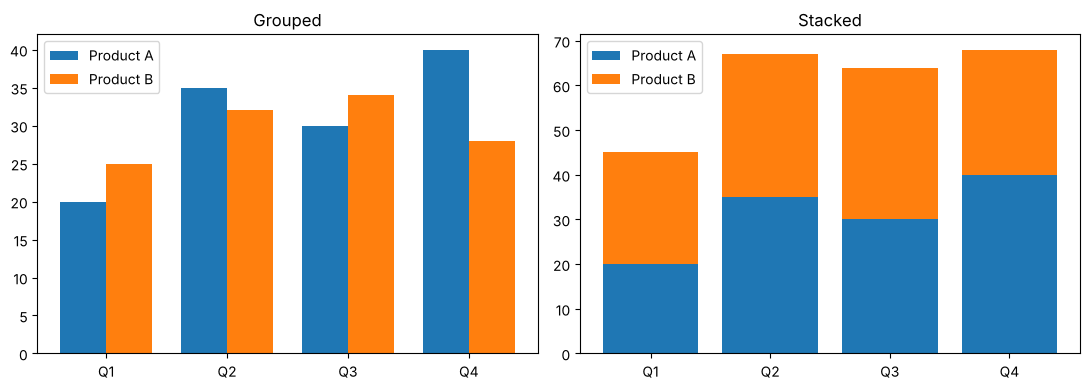

In [6]:
quarters = ["Q1", "Q2", "Q3", "Q4"]
product_a = np.array([20, 35, 30, 40])
product_b = np.array([25, 32, 34, 28])
idx = np.arange(len(quarters))
w = 0.38

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Grouped
ax1.bar(idx - w / 2, product_a, w, label="Product A")
ax1.bar(idx + w / 2, product_b, w, label="Product B")
ax1.set_xticks(idx, quarters)
ax1.set_title("Grouped")
ax1.legend()

# Stacked
ax2.bar(quarters, product_a, label="Product A")
ax2.bar(quarters, product_b, bottom=product_a, label="Product B")
ax2.set_title("Stacked")
ax2.legend()

plt.tight_layout()
plt.show()

### 1.6 Histogram, box plot and pie chart

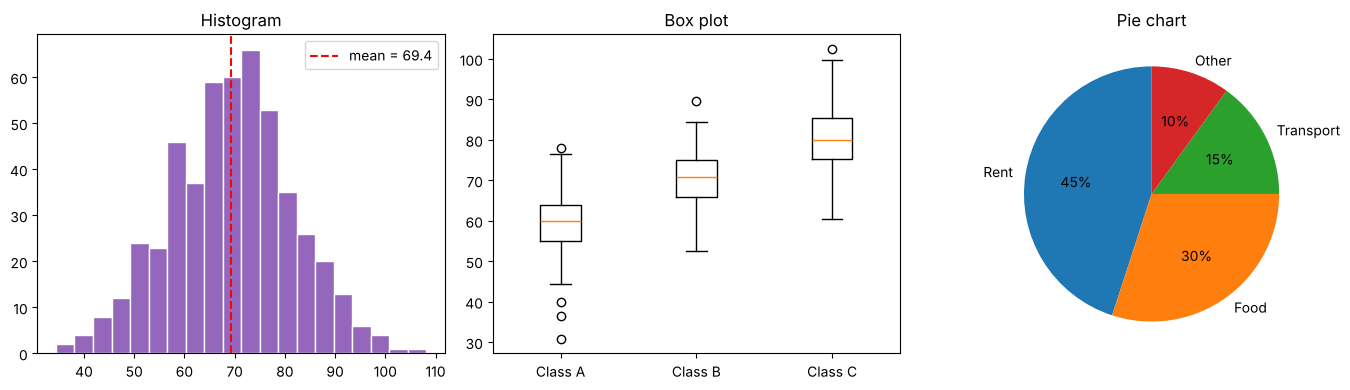

In [7]:
scores = rng.normal(70, 12, 500)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(scores, bins=20, color="tab:purple", edgecolor="white")
axes[0].axvline(scores.mean(), color="red", linestyle="--", label=f"mean = {scores.mean():.1f}")
axes[0].set_title("Histogram")
axes[0].legend()

group_data = [rng.normal(m, 8, 100) for m in (60, 70, 80)]
axes[1].boxplot(group_data, tick_labels=["Class A", "Class B", "Class C"])
axes[1].set_title("Box plot")

axes[2].pie([45, 30, 15, 10], labels=["Rent", "Food", "Transport", "Other"],
            autopct="%1.0f%%", startangle=90)
axes[2].set_title("Pie chart")

plt.tight_layout()
plt.show()

### 1.7 Subplots grid and annotations

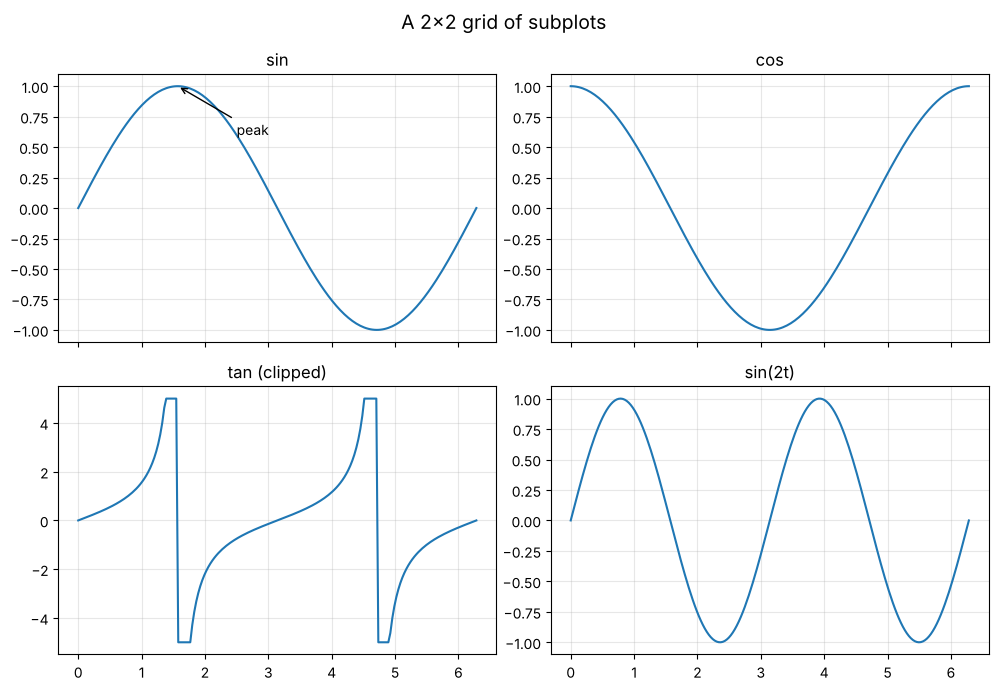

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True)
t = np.linspace(0, 2 * np.pi, 200)

for ax, (name, y) in zip(axes.ravel(), {"sin": np.sin(t), "cos": np.cos(t),
                                         "tan (clipped)": np.clip(np.tan(t), -5, 5),
                                         "sin(2t)": np.sin(2 * t)}.items()):
    ax.plot(t, y)
    ax.set_title(name)
    ax.grid(alpha=0.3)

axes[0, 0].annotate("peak", xy=(np.pi / 2, 1), xytext=(2.5, 0.6),
                    arrowprops=dict(arrowstyle="->"))

fig.suptitle("A 2×2 grid of subplots", fontsize=14)
plt.tight_layout()
plt.show()

### 1.8 Time series and saving a figure

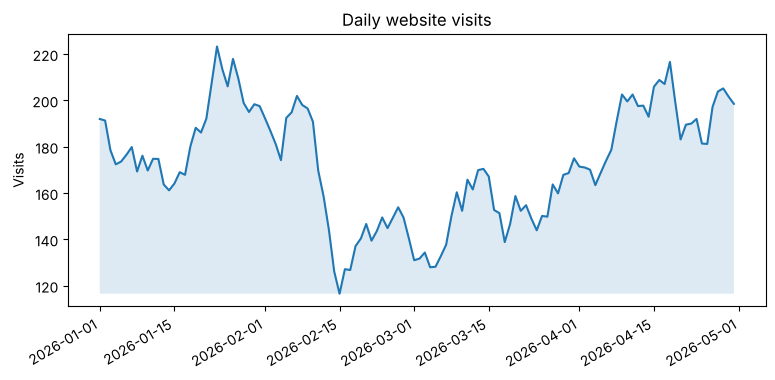

saved: visits.png True


In [9]:
dates = pd.date_range("2026-01-01", periods=120, freq="D")
visits = 200 + np.cumsum(rng.normal(0, 8, 120))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(dates, visits, color="tab:blue")
ax.fill_between(dates, visits, visits.min(), alpha=0.15)
ax.set_title("Daily website visits")
ax.set_ylabel("Visits")
fig.autofmt_xdate()

import tempfile
out_path = os.path.join(tempfile.mkdtemp(), "visits.png")
fig.savefig(out_path, dpi=150, bbox_inches="tight")     # png, pdf, svg all work
plt.show()
print("saved:", os.path.basename(out_path), os.path.getsize(out_path) > 0)

---
## Part 2 — Seaborn

Seaborn builds on Matplotlib to make **statistical** plots with less code and nicer defaults. It works directly with DataFrames: pass `data=`, then name the columns for `x`, `y` and `hue` (color grouping).

In [11]:
sns.set_theme(style="whitegrid", context="notebook", palette="deep")

# Build a sample dataset (no internet needed)
n = 300
dept = rng.choice(["Sales", "IT", "HR", "Ops"], n, p=[0.3, 0.35, 0.15, 0.2])
years = rng.integers(0, 20, n)
base = {"Sales": 45, "IT": 60, "HR": 48, "Ops": 50}
salary = np.array([base[d] for d in dept]) + years * 1.8 + rng.normal(0, 6, n)
satisfaction = np.clip(6 + 0.08 * years + rng.normal(0, 1.5, n), 1, 10)
gender = rng.choice(["F", "M"], n)

people = pd.DataFrame({"dept": dept, "years": years, "salary": salary.round(1),
                       "satisfaction": satisfaction.round(1), "gender": gender})
people.head()

,dept,years,salary,satisfaction,gender
0,IT,14,80.3,5.6,F
1,IT,17,91.3,7.8,M
2,Ops,10,65.7,8.2,F
3,Ops,12,80.5,8.0,F
4,Ops,14,78.2,10.0,M


### 2.1 Distributions: histogram, KDE

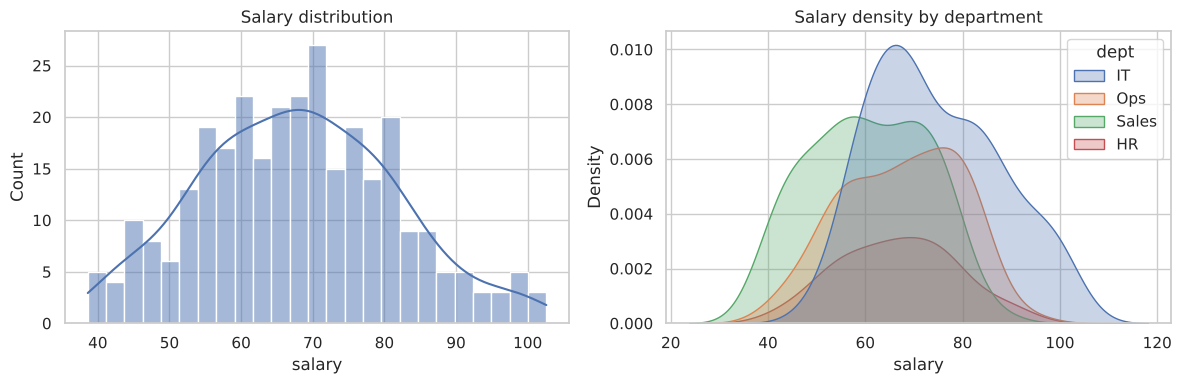

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=people, x="salary", bins=25, kde=True, ax=axes[0])
axes[0].set_title("Salary distribution")

sns.kdeplot(data=people, x="salary", hue="dept", fill=True, alpha=0.3, ax=axes[1])
axes[1].set_title("Salary density by department")

plt.tight_layout()
plt.show()

### 2.2 Categorical plots: count, bar, box, violin

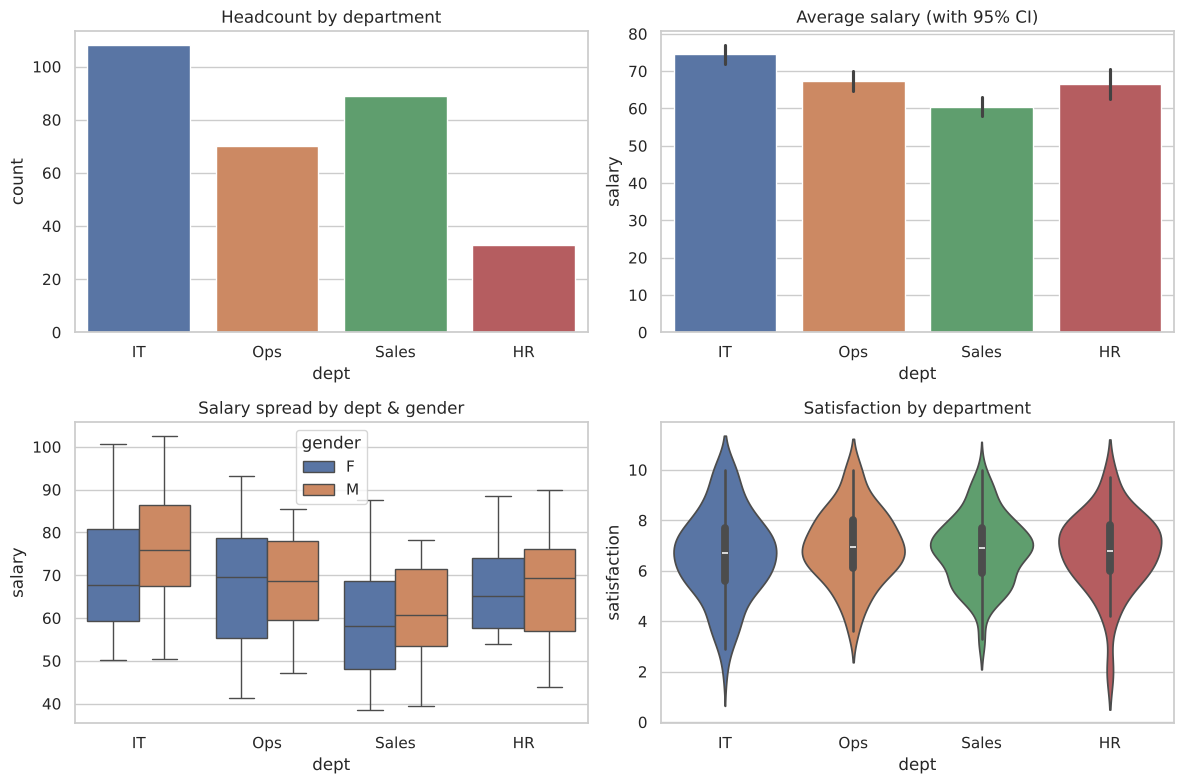

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.countplot(data=people, x="dept", hue="dept", legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Headcount by department")

sns.barplot(data=people, x="dept", y="salary", hue="dept", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Average salary (with 95% CI)")

sns.boxplot(data=people, x="dept", y="salary", hue="gender", ax=axes[1, 0])
axes[1, 0].set_title("Salary spread by dept & gender")

sns.violinplot(data=people, x="dept", y="satisfaction", hue="dept", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Satisfaction by department")

plt.tight_layout()
plt.show()

### 2.3 Relationships: scatter and regression

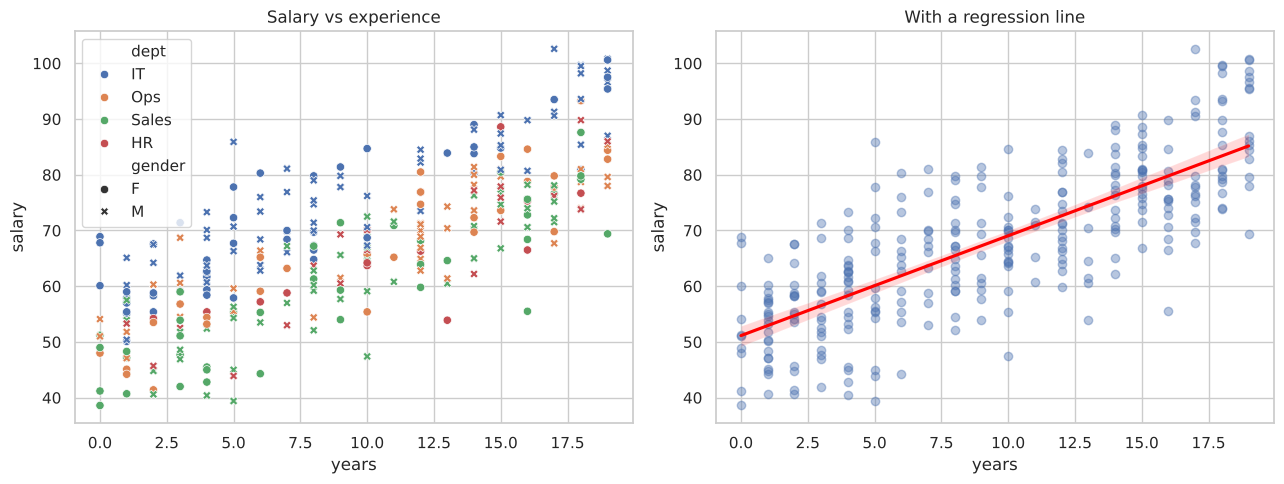

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=people, x="years", y="salary", hue="dept", style="gender", ax=axes[0])
axes[0].set_title("Salary vs experience")

sns.regplot(data=people, x="years", y="salary", scatter_kws={"alpha": 0.4}, line_kws={"color": "red"}, ax=axes[1])
axes[1].set_title("With a regression line")

plt.tight_layout()
plt.show()

### 2.4 Correlation heatmap

              years  salary  satisfaction
years          1.00    0.77          0.24
salary         0.77    1.00          0.20
satisfaction   0.24    0.20          1.00


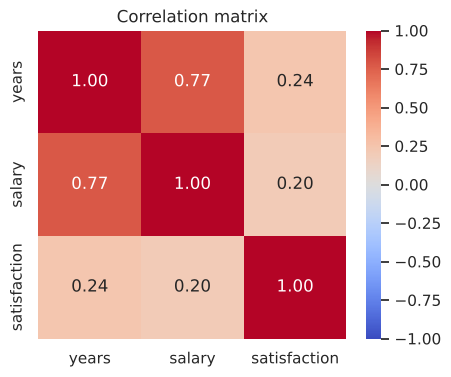

In [15]:
corr = people[["years", "salary", "satisfaction"]].corr()
print(corr.round(2))

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation matrix")
plt.show()

### 2.5 Pair plot and joint plot

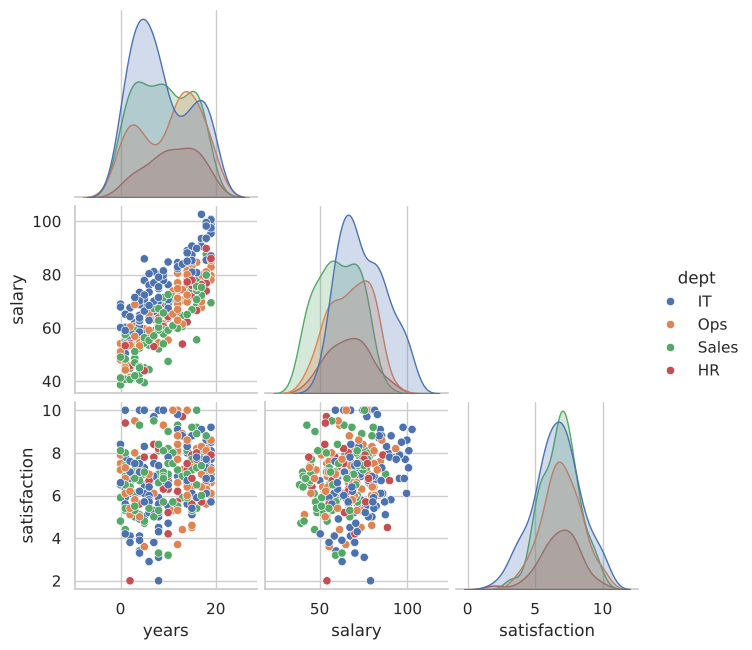

In [16]:
sns.pairplot(people, vars=["years", "salary", "satisfaction"], hue="dept", height=2.2, corner=True)
plt.show()

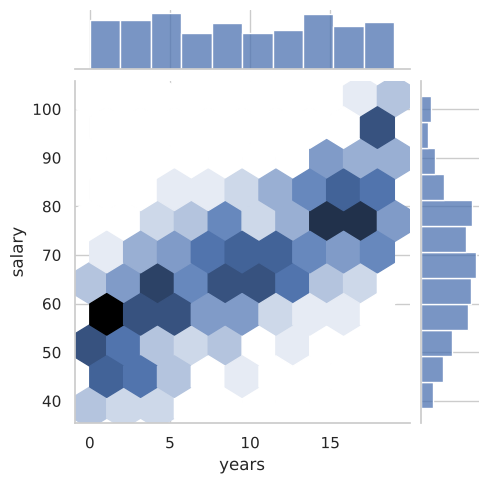

In [17]:
sns.jointplot(data=people, x="years", y="salary", kind="hex", height=5)
plt.show()

### 2.6 Faceting: one chart per category

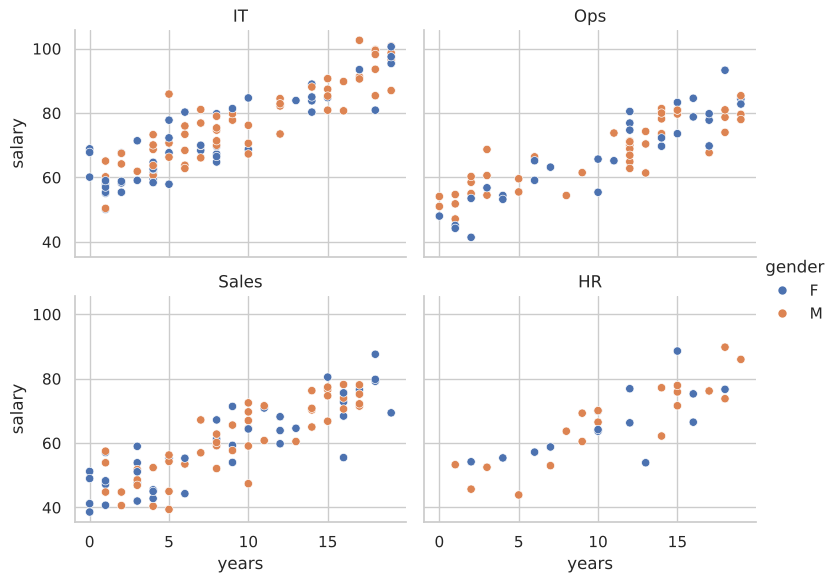

In [18]:
g = sns.relplot(data=people, x="years", y="salary", col="dept", col_wrap=2,
                hue="gender", height=3, aspect=1.3)
g.set_titles("{col_name}")
plt.show()

---
## Part 3 — TensorFlow Intro: Install & Tensors

**TensorFlow** is Google's open-source library for machine learning. Its core data structure is the **tensor**: a multi-dimensional array (like NumPy's `ndarray`) that can also run on GPUs and track gradients.



### 3.2 Verify the installation

In [20]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Eager execution  :", tf.executing_eagerly())
print("GPUs found       :", tf.config.list_physical_devices("GPU"))
print("CPUs found       :", len(tf.config.list_physical_devices("CPU")))

# Smoke test
print(tf.reduce_sum(tf.random.normal([1000, 1000])).numpy() is not None)

TensorFlow version: 2.21.0
Eager execution  : True
GPUs found       : []
CPUs found       : 1
True


In [21]:
scalar = tf.constant(5)
vector = tf.constant([1.0, 2.0, 3.0])
matrix = tf.constant([[1, 2], [3, 4]])
tensor3d = tf.constant([[[1, 2], [3, 4]], [[5, 6], [7, 8]]])

for name, t in [("scalar", scalar), ("vector", vector), ("matrix", matrix), ("3-D", tensor3d)]:
    print(f"{name:7} rank={tf.rank(t).numpy()} shape={t.shape} dtype={t.dtype.name}")

print(matrix)

scalar  rank=0 shape=() dtype=int32
vector  rank=1 shape=(3,) dtype=float32
matrix  rank=2 shape=(2, 2) dtype=int32
3-D     rank=3 shape=(2, 2, 2) dtype=int32
tf.Tensor(
[[1 2]
 [3 4]], shape=(2, 2), dtype=int32)


### 3.4 Creating tensors

In [22]:
print(tf.zeros([2, 3]).numpy())
print(tf.ones([2, 2]).numpy())
print(tf.fill([2, 3], 7).numpy())
print(tf.range(0, 10, 2).numpy())
print(tf.linspace(0.0, 1.0, 5).numpy())
print(tf.eye(3).numpy())

tf.random.set_seed(42)
print(tf.random.uniform([2, 3], minval=0, maxval=1).numpy().round(3))
print(tf.random.normal([2, 3], mean=0.0, stddev=1.0).numpy().round(3))

[[0. 0. 0.]
 [0. 0. 0.]]
[[1. 1.]
 [1. 1.]]
[[7 7 7]
 [7 7 7]]
[0 2 4 6 8]
[0.   0.25 0.5  0.75 1.  ]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[[0.665 0.441 0.353]
 [0.464 0.034 0.685]]
[[ 0.084 -0.861  0.378]
 [-0.005 -0.495  0.618]]


### 3.5 Data types and casting

In [23]:
a = tf.constant([1, 2, 3])                      # int32
b = tf.constant([1.5, 2.5, 3.5])                # float32
print(a.dtype, b.dtype)

c = tf.cast(a, tf.float32)
print(c.dtype, (c + b).numpy())

# TensorFlow does NOT auto-convert between dtypes
try:
    a + b
except Exception as e:
    print(type(e).__name__, "-> cast first")

print(tf.cast([0.0, 1.0, 2.0], tf.bool).numpy())

<dtype: 'int32'> <dtype: 'float32'>
<dtype: 'float32'> [2.5 4.5 6.5]
InvalidArgumentError -> cast first
[False  True  True]


### 3.6 Shapes, indexing and reshaping

In [24]:
t = tf.reshape(tf.range(12), (3, 4))
print(t.numpy())

print(t[0].numpy())            # first row
print(t[:, 1].numpy())         # second column
print(t[1:, 2:].numpy())       # sub-block
print(t[-1, -1].numpy())       # last element

print(tf.reshape(t, (2, 6)).shape)
print(tf.reshape(t, (-1,)).shape)         # flatten
print(tf.transpose(t).shape)
print(tf.expand_dims(t, axis=0).shape)    # add batch dimension
print(tf.squeeze(tf.zeros([1, 3, 1])).shape)

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
[0 1 2 3]
[1 5 9]
[[ 6  7]
 [10 11]]
11
(2, 6)
(12,)
(4, 3)
(1, 3, 4)
(3,)


### 3.7 Math with tensors

In [25]:
x = tf.constant([[1.0, 2.0], [3.0, 4.0]])
y = tf.constant([[5.0, 6.0], [7.0, 8.0]])

print("add     :", (x + y).numpy().tolist())
print("multiply:", (x * y).numpy().tolist())        # elementwise
print("matmul  :", tf.matmul(x, y).numpy().tolist())  # same as x @ y
print("power   :", (x ** 2).numpy().tolist())
print("sqrt    :", tf.sqrt(x).numpy().round(3).tolist())

# Reductions
print("sum all :", tf.reduce_sum(x).numpy())
print("col sums:", tf.reduce_sum(x, axis=0).numpy())
print("row mean:", tf.reduce_mean(x, axis=1).numpy())
print("max     :", tf.reduce_max(x).numpy(), "| argmax per row:", tf.argmax(x, axis=1).numpy())

# Broadcasting works like NumPy
print((x + tf.constant([10.0, 20.0])).numpy().tolist())

add     : [[6.0, 8.0], [10.0, 12.0]]
multiply: [[5.0, 12.0], [21.0, 32.0]]


matmul  : [[19.0, 22.0], [43.0, 50.0]]
power   : [[1.0, 4.0], [9.0, 16.0]]
sqrt    : [[1.0, 1.4140000343322754], [1.7319999933242798, 2.0]]
sum all : 10.0
col sums: [4. 6.]
row mean: [1.5 3.5]
max     : 4.0 | argmax per row: [1 1]
[[11.0, 22.0], [13.0, 24.0]]


### 3.8 Concatenating and stacking

In [26]:
a = tf.constant([[1, 2], [3, 4]])
b = tf.constant([[5, 6], [7, 8]])

print(tf.concat([a, b], axis=0).shape)   # (4, 2)
print(tf.concat([a, b], axis=1).shape)   # (2, 4)
print(tf.stack([a, b], axis=0).shape)    # (2, 2, 2), a NEW axis

(4, 2)
(2, 4)
(2, 2, 2)


### 3.9 NumPy interoperability

In [27]:
arr = np.array([[1.0, 2.0], [3.0, 4.0]])

t = tf.constant(arr)              # NumPy -> tensor
back = t.numpy()                  # tensor -> NumPy
print(type(t).__name__, type(back).__name__)

print(np.sqrt(t))                 # NumPy functions accept tensors
print(tf.square(arr))             # TF functions accept arrays

EagerTensor ndarray
[[1.         1.41421356]
 [1.73205081 2.        ]]
tf.Tensor(
[[ 1.  4.]
 [ 9. 16.]], shape=(2, 2), dtype=float64)


### 3.10 `tf.constant` vs `tf.Variable`
- **Constant** tensors are **immutable**.
- **Variables** hold **mutable state** (like model weights) and are updated during training.

In [28]:
const = tf.constant([1.0, 2.0, 3.0])
try:
    const[0].assign(10.0)
except AttributeError:
    print("constants can't be modified")

var = tf.Variable([1.0, 2.0, 3.0], name="weights")
var.assign([10.0, 20.0, 30.0])        # replace values
var.assign_add([1.0, 1.0, 1.0])       # in-place add
print(var.numpy(), "| trainable:", var.trainable)

constants can't be modified
[11. 21. 31.] | trainable: True


### 3.11 Automatic differentiation with `GradientTape`
TensorFlow can compute derivatives automatically, which is the engine behind training neural networks.

In [29]:
x = tf.Variable(3.0)

with tf.GradientTape() as tape:
    y = x ** 2 + 2 * x + 1           # y = x² + 2x + 1

dy_dx = tape.gradient(y, x)          # dy/dx = 2x + 2 = 8 at x = 3
print("y =", y.numpy(), "| dy/dx =", dy_dx.numpy())

y = 16.0 | dy/dx = 8.0


### 3.12 Mini demo: fit a line with gradient descent

learned w = 3.01 (true 3), b = 2.01 (true 2)


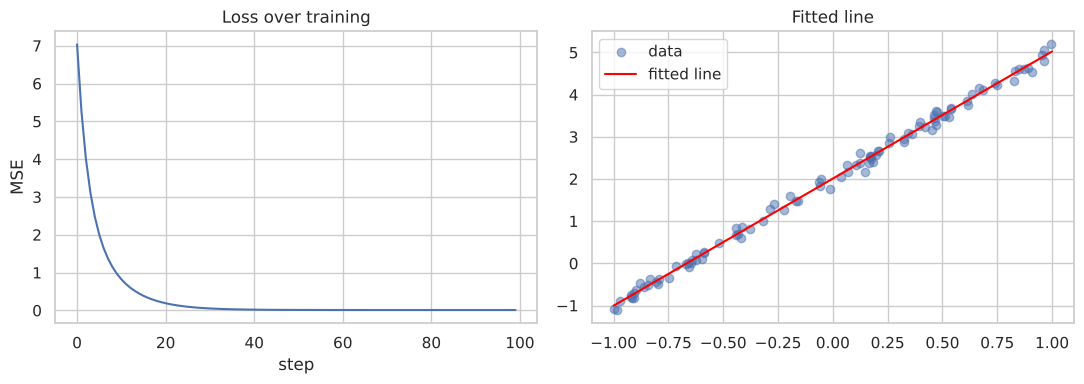

In [30]:
tf.random.set_seed(0)

# Data: y = 3x + 2 + noise
X = tf.random.uniform([100], -1, 1)
Y = 3 * X + 2 + tf.random.normal([100], stddev=0.1)

w = tf.Variable(0.0)
b = tf.Variable(0.0)
lr = 0.1
history = []

for step in range(100):
    with tf.GradientTape() as tape:
        pred = w * X + b
        loss = tf.reduce_mean((pred - Y) ** 2)
    dw, db = tape.gradient(loss, [w, b])
    w.assign_sub(lr * dw)
    b.assign_sub(lr * db)
    history.append(loss.numpy())

print(f"learned w = {w.numpy():.2f} (true 3), b = {b.numpy():.2f} (true 2)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history)
axes[0].set_title("Loss over training")
axes[0].set_xlabel("step")
axes[0].set_ylabel("MSE")

axes[1].scatter(X, Y, alpha=0.5, label="data")
xs = np.linspace(-1, 1, 50)
axes[1].plot(xs, w.numpy() * xs + b.numpy(), color="red", label="fitted line")
axes[1].legend()
axes[1].set_title("Fitted line")
plt.tight_layout()
plt.show()

---
## Part 4 — CSV Analysis Task

**Scenario:** You're given `sales.csv` from a retail company. Clean it, explore it, visualize it and answer business questions.



In [32]:
import tempfile

# ---- Generate a messy sample CSV (skip this when using your own data) ----
r = np.random.default_rng(2026)
n = 600
regions = ["North", "South", "East", "West"]
products = {"Laptop": 900, "Phone": 600, "Tablet": 400, "Headphones": 120, "Monitor": 250}

gen = pd.DataFrame({
    "order_id": np.arange(1001, 1001 + n),
    "date": pd.to_datetime("2026-01-01") + pd.to_timedelta(r.integers(0, 270, n), unit="D"),
    "region": r.choice(regions, n, p=[0.3, 0.25, 0.25, 0.2]),
    "product": r.choice(list(products), n, p=[0.15, 0.25, 0.15, 0.3, 0.15]),
    "units": r.integers(1, 6, n),
    "discount": r.choice([0, 0.05, 0.10, 0.20], n, p=[0.5, 0.25, 0.15, 0.1]),
    "customer_rating": r.integers(1, 6, n).astype(float),
})
gen["unit_price"] = gen["product"].map(products) * r.uniform(0.95, 1.05, n)
gen["unit_price"] = gen["unit_price"].round(2)

# Make it messy
gen.loc[r.choice(n, 25, replace=False), "customer_rating"] = np.nan
gen.loc[r.choice(n, 15, replace=False), "region"] = None
gen.loc[r.choice(n, 10, replace=False), "units"] = np.nan
gen.loc[r.choice(n, 8, replace=False), "region"] = "  north "          # inconsistent text
gen["product"] = gen["product"].where(r.random(n) > 0.03, gen["product"].str.lower())
gen = pd.concat([gen, gen.sample(6, random_state=1)], ignore_index=True)   # duplicates
gen["date"] = gen["date"].dt.strftime("%Y-%m-%d")

csv_path = os.path.join(tempfile.mkdtemp(), "sales.csv")
gen.to_csv(csv_path, index=False)
print("Created", csv_path.split(os.sep)[-1], "with", len(gen), "rows")

Created sales.csv with 606 rows


### Step 1 — Load and inspect

In [33]:
df = pd.read_csv(csv_path)

print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (606, 8)


,order_id,date,region,product,units,discount,customer_rating,unit_price
0,1001,2026-08-19,East,Headphones,1.0,0.05,3.0,125.84
1,1002,2026-02-18,South,Monitor,2.0,0.00,3.0,242.23
2,1003,2026-01-08,North,Tablet,4.0,0.20,2.0,381.76
3,1004,2026-06-22,South,Phone,3.0,0.20,5.0,600.92
4,1005,2026-04-09,North,Laptop,3.0,0.00,5.0,865.68


<class 'pandas.DataFrame'>
RangeIndex: 606 entries, 0 to 605
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         606 non-null    int64  
 1   date             606 non-null    str    
 2   region           591 non-null    str    
 3   product          606 non-null    str    
 4   units            596 non-null    float64
 5   discount         606 non-null    float64
 6   customer_rating  581 non-null    float64
 7   unit_price       606 non-null    float64
dtypes: float64(4), int64(1), str(3)
memory usage: 38.0 KB


In [34]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nRegions:", df["region"].unique())
print("Products:", df["product"].unique())
display(df.describe().round(2))

Missing values per column:
order_id            0
date                0
region             15
product             0
units              10
discount            0
customer_rating    25
unit_price          0
dtype: int64

Duplicate rows: 6

Regions: <StringArray>
['East', 'South', 'North', 'West', nan, '  north ']
Length: 6, dtype: str
Products: <StringArray>
['Headphones',    'Monitor',     'Tablet',      'Phone',     'Laptop',
     'tablet',      'phone',    'monitor', 'headphones',     'laptop']
Length: 10, dtype: str


,order_id,units,discount,customer_rating,unit_price
count,606.00,596.00,606.00,581.00,606.00
mean,1300.90,2.97,0.05,2.90,420.03
std,173.38,1.39,0.06,1.36,278.42
min,1001.00,1.00,0.00,1.00,114.04
25%,1151.25,2.00,0.00,2.00,123.78
50%,1301.50,3.00,0.00,3.00,389.54
75%,1450.75,4.00,0.09,4.00,608.93
max,1600.00,5.00,0.20,5.00,944.69


### Step 2 — Clean

In [35]:
clean = df.copy()

# 1. Remove exact duplicate rows
clean = clean.drop_duplicates()

# 2. Fix text inconsistencies
clean["region"] = clean["region"].str.strip().str.title()
clean["product"] = clean["product"].str.strip().str.title()

# 3. Parse dates
clean["date"] = pd.to_datetime(clean["date"])

# 4. Handle missing values
clean["region"] = clean["region"].fillna("Unknown")
clean["units"] = clean["units"].fillna(clean["units"].median()).astype(int)
clean["customer_rating"] = clean["customer_rating"].fillna(clean["customer_rating"].median())

# 5. Feature engineering
clean["revenue"] = clean["units"] * clean["unit_price"] * (1 - clean["discount"])
clean["month"] = clean["date"].dt.to_period("M")
clean["weekday"] = clean["date"].dt.day_name()

print("Rows:", len(df), "->", len(clean))
print("Missing left:", clean.isna().sum().sum())
print(clean["region"].unique(), clean["product"].unique())
clean.head()

Rows: 606 -> 600
Missing left: 0
<StringArray>
['East', 'South', 'North', 'West', 'Unknown']
Length: 5, dtype: str <StringArray>
['Headphones', 'Monitor', 'Tablet', 'Phone', 'Laptop']
Length: 5, dtype: str


,order_id,date,region,product,units,discount,customer_rating,unit_price,revenue,month,weekday
0,1001,2026-08-19,East,Headphones,1,0.05,3.0,125.84,119.548,2026-08,Wednesday
1,1002,2026-02-18,South,Monitor,2,0.00,3.0,242.23,484.460,2026-02,Wednesday
2,1003,2026-01-08,North,Tablet,4,0.20,2.0,381.76,1221.632,2026-01,Thursday
3,1004,2026-06-22,South,Phone,3,0.20,5.0,600.92,1442.208,2026-06,Monday
4,1005,2026-04-09,North,Laptop,3,0.00,5.0,865.68,2597.040,2026-04,Thursday


### Step 3 — Explore: summary statistics

In [36]:
print(f"Total revenue : {clean['revenue'].sum():,.0f}")
print(f"Orders        : {len(clean)}")
print(f"Avg order     : {clean['revenue'].mean():,.2f}")
print(f"Avg rating    : {clean['customer_rating'].mean():.2f}")

by_region = clean.groupby("region").agg(orders=("order_id", "count"),
                                        revenue=("revenue", "sum"),
                                        avg_rating=("customer_rating", "mean")).round(1)
display(by_region.sort_values("revenue", ascending=False))

by_product = clean.groupby("product").agg(units=("units", "sum"),
                                          revenue=("revenue", "sum")).sort_values("revenue", ascending=False).round(0)
display(by_product)

Total revenue : 704,279
Orders        : 600
Avg order     : 1,173.80
Avg rating    : 2.91


,orders,revenue,avg_rating
region,,,
North,165,192340.1,2.9
East,160,191761.3,2.9
South,133,159543.4,3.1
West,127,147218.6,2.8
Unknown,15,13415.5,3.0


,units,revenue
product,,
Phone,444,251368.0
Laptop,277,236709.0
Tablet,216,82589.0
Monitor,296,70934.0
Headphones,550,62679.0


### Step 4 — Visualize

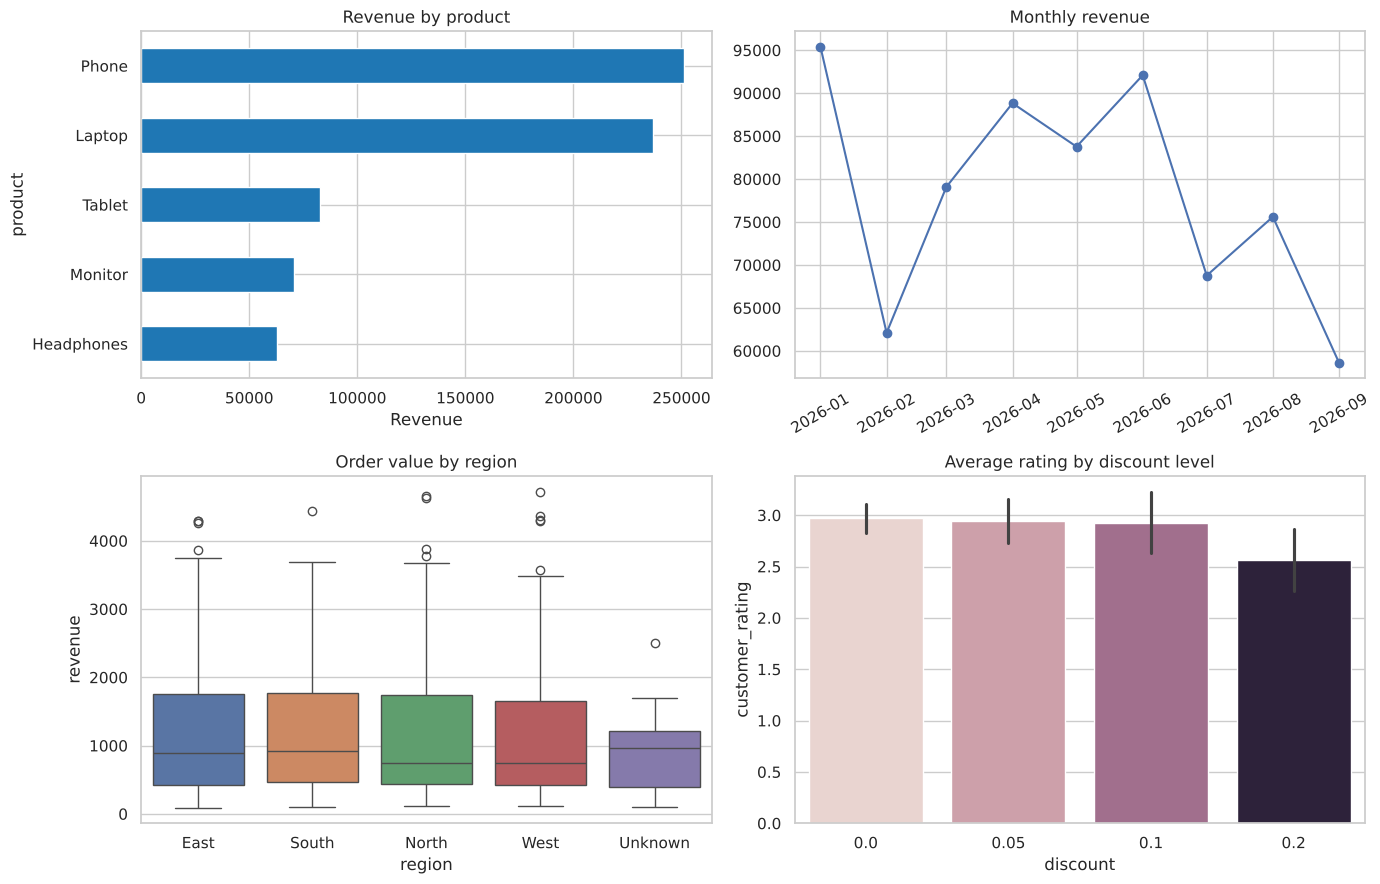

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# (a) Revenue by product
by_product["revenue"].plot.barh(ax=axes[0, 0], color="tab:blue")
axes[0, 0].set_title("Revenue by product")
axes[0, 0].invert_yaxis()
axes[0, 0].set_xlabel("Revenue")

# (b) Monthly revenue trend
monthly = clean.groupby("month")["revenue"].sum()
axes[0, 1].plot(monthly.index.to_timestamp(), monthly.values, marker="o")
axes[0, 1].set_title("Monthly revenue")
axes[0, 1].tick_params(axis="x", rotation=30)

# (c) Revenue distribution by region
sns.boxplot(data=clean, x="region", y="revenue", hue="region", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Order value by region")

# (d) Discount vs rating
sns.barplot(data=clean, x="discount", y="customer_rating", hue="discount", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Average rating by discount level")

plt.tight_layout()
plt.show()

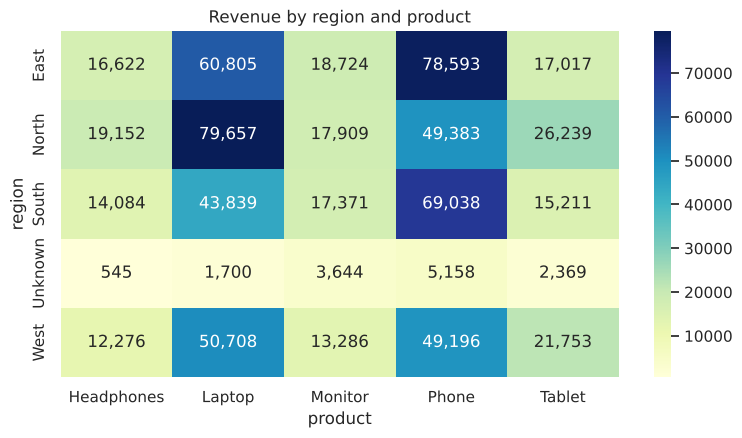

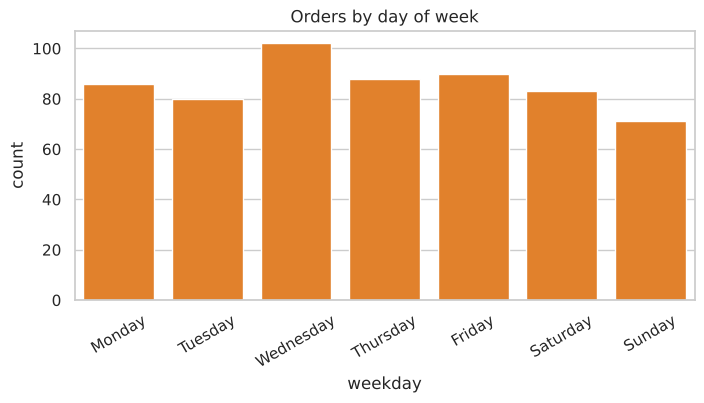

In [38]:
# Heatmap: revenue by region and product
pivot = clean.pivot_table(index="region", columns="product", values="revenue", aggfunc="sum")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="YlGnBu", ax=ax)
ax.set_title("Revenue by region and product")
plt.show()

# Orders by weekday
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.countplot(data=clean, x="weekday", order=order, color="tab:orange", ax=ax)
ax.set_title("Orders by day of week")
plt.xticks(rotation=30)
plt.show()

### Step 5 — Answer the business questions

In [39]:
top_product = by_product["revenue"].idxmax()
best_region = by_region["revenue"].idxmax()
best_month = monthly.idxmax()
corr = clean[["discount", "units", "customer_rating", "revenue"]].corr()["revenue"].drop("revenue")

print("1. Top product by revenue :", top_product)
print("2. Best region by revenue :", best_region)
print("3. Strongest month        :", best_month, f"({monthly.max():,.0f})")
print("4. Share of top 3 orders' revenue:",
      f"{clean.nlargest(3, 'revenue')['revenue'].sum() / clean['revenue'].sum():.1%}")
print("5. Correlation with revenue:")
print(corr.round(2).to_string())

lowrated = clean[clean["customer_rating"] <= 2].groupby("product").size().sort_values(ascending=False)
print("\n6. Products with the most low ratings (<=2):")
print(lowrated.to_string())

1. Top product by revenue : Phone
2. Best region by revenue : North
3. Strongest month        : 2026-01 (95,397)
4. Share of top 3 orders' revenue: 2.0%
5. Correlation with revenue:
discount          -0.06
units              0.51
customer_rating    0.00

6. Products with the most low ratings (<=2):
product
Headphones    79
Phone         56
Laptop        38
Monitor       38
Tablet        32


### Step 6 — Save the cleaned data

In [40]:
out_dir = os.path.dirname(csv_path)
clean_path = os.path.join(out_dir, "sales_clean.csv")
clean.drop(columns="month").to_csv(clean_path, index=False)
print("Saved:", os.path.basename(clean_path), "|", os.path.getsize(clean_path), "bytes")

Saved: sales_clean.csv | 39287 bytes


### CSV analysis checklist (reuse on any dataset)
1. **Load**: `read_csv`; check `shape`, `head`, `info`, `describe`.
2. **Audit**: missing values, duplicates, odd categories, wrong dtypes.
3. **Clean**: dedupe, normalize text, parse dates, fill/drop missing values.
4. **Engineer**: add columns that answer your questions (revenue, month, ...).
5. **Explore**: `groupby`, `pivot_table`, correlations.
6. **Visualize**: choose a chart for each question.
7. **Conclude**: write the answers in plain language.
8. **Save**: export the cleaned file.

